In [1]:
import torch 
import sys 
import pandas as pd 
import numpy as np 
import networkx as nx 

print(f'torch=={torch.__version__}') 
print(f'pandas=={pd.__version__}') 
print(f'numpy=={np.__version__}') 
print(f'networkx=={nx.__version__}') 

import tqdm 
import matplotlib.pyplot as plt 
from itertools import chain 

sys.path.append('.') 
from agfn.gflownet import GFlowNet 
from agfn.gym import MAG, LogReward 
from agfn.models import ForwardPolicy, BackwardPolicy  

torch==2.2.1+cu121
pandas==2.2.2
numpy==1.26.3
networkx==3.3


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') 
print(f'Device: {device}') 

Device: cuda


This tutorial shows how to train an AGFN using a custom dataset. In the near future, it will be expanded and improved. 

## Load the data

In [3]:
torch.set_default_dtype(torch.float64) 

In [4]:
data = pd.read_csv('data/chain4_dat01.csv') 
node_labels = data.columns.tolist() 
data = torch.tensor(data.values, device=device, dtype=torch.get_default_dtype()) 
num_nodes = data.shape[1] 
print(f'Number of variables: {num_nodes}') 

Number of variables: 4


## Instantiate the model 

In [5]:
pf = ForwardPolicy(num_nodes, num_layers=2, hidden_dim=256, device=device) 
pb = BackwardPolicy(device) 
gflownet = GFlowNet(pf, pb, criterion='tb', device=device) 

In [6]:
create_env = lambda batch_size=64: MAG(num_nodes, batch_size, log_reward, device=device) 

In [7]:
log_reward = LogReward(dataset=data, device=device) 
log_reward.warmup(gflownet, create_env, 32)

## Train the model 

In [8]:
def train(gflownet, create_env, epochs, lr=1e-3, lr_logz=1e-1, use_scheduler=False):
    optimizer = torch.optim.Adam([
        {'params': chain(gflownet.pf.parameters(), gflownet.pb.parameters()), 'lr': lr}, 
        {'params': gflownet.log_z, 'lr': lr_logz}]) 
    scheduler = torch.optim.lr_scheduler.PolynomialLR(optimizer, total_iters=epochs) 

    losses = list() 
    pbar = tqdm.tqdm(range(epochs), disable=False) 
    for epoch in pbar: 
        optimizer.zero_grad() 
        env = create_env() 
        loss = gflownet(env) 
        loss.backward()     
        optimizer.step() 
        pbar.set_postfix(loss=loss.item()) 
        # Update the exploration rate 
        losses.append(loss.item()) 
        if use_scheduler: 
            scheduler.step() 
    return losses  

In [9]:
losses = train(gflownet, create_env, epochs=int(512)) 

  0%|          | 0/512 [00:00<?, ?it/s]

100%|██████████| 512/512 [00:19<00:00, 26.81it/s, loss=0.0324]


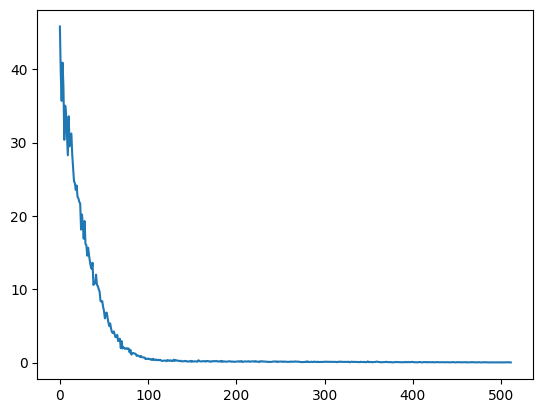

In [10]:
plt.plot(losses) 

## Sample from target 

In [11]:
gflownet.eval() 
env = create_env() 
env = gflownet.sample(env) 

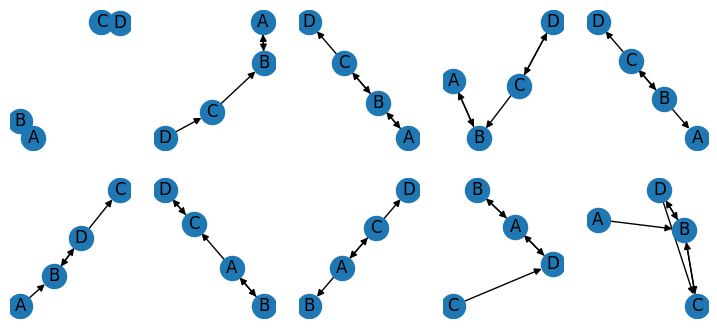

In [12]:
plt.figure(figsize=(9, 4)) 
indices = torch.topk(env.log_reward(), k=10).indices 
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)  
    env.draw(i, labels=node_labels) 

## Human-in-the-loop pipeline  

We provide below an example of how to use the principled HITL pipeline of our work or a pragmatic, probably more useful, instantiation of it. 

The original code was heavily tailored to the estimation of functionals and not so much for sampling. 

We recall that a graph of $n$ nodes is represented by a matrix $\mathbf{A} = \{1, 0\}^{{n \choose 2} \times 4}$. Each row of $\mathbf{A}$ is an indicator function representing the direction of the edge. 

In particular, for each $i < j$, $A_{ij} = (1, 0, 0, 0)$ represents an inexisting edge; $A_{ij} = (0, 1, 0, 0)$ represents an edge from $i$ to $j$, etc. Please refer to `hitl.EdgeType`. 

The expert feedback is represented as a probability vector $\mathbf{p} \in \{1, 0\}^{d}$ denoting the expert's confidence on each relationship.  

In [ ]:
def get_expert_feedback(query): 
    true_graph = torch.tensor([
        [0, 1, 0, 0], # (A, B)
        [1, 0, 0, 0], # (A, C)
        [1, 0, 0, 0], # (A, D)
        [0, 1, 0, 0], # (B, C)
        [1, 0, 0, 0], # (B, D)
        [0, 1, 0, 0], # (C, D) 
    ], device=device) 
    return true_graph[query] # The expert is an oracle 

pi = .99 # our confidence on the expert  

Calculate the model-based prior and declare the (currently empty) list of feedbacks and queries. 

In [53]:
## Sample a batch of graphs 
from agfn.hitl import sample_massive_batch, nquery, sample_from_expert, edge_marks_to_adj, fpost 

In [54]:
gflownet.eval() 
graphs, _, log_rewards = sample_massive_batch(gflownet, create_env, num_batches=128) 

  9%|▉         | 12/127 [00:00<00:03, 35.45it/s]

100%|██████████| 127/127 [00:03<00:00, 36.64it/s]


The prior distribution is a matrix $\mathbf{P} \in \mathbb{R}^{{n \choose 2} \times 4}$ in which each row represents a probability distribution over the each relationship. 

In [55]:
priors = graphs.edge_marks.float().mean(dim=0)  

In [56]:
num_hitl_rounds = 5 # Maximum number of feedbacks (<= maximum number of edges) 

In [57]:
feedbacks = torch.zeros((0,), dtype=torch.long, device=device) # list of 0-3 integers representing the feedback
queries = torch.zeros((0,), dtype=torch.long, device=device) # list of edge indexes corresponding to the feedback

for round in range(num_hitl_rounds): 
    # Elicit a novel query 
    query = nquery(
        graphs.edge_marks, log_rewards, feedbacks, priors, queries, pi 
    )

    # Sample from the expert's distribution  
    expert_confidence = get_expert_feedback(query) 
    fprob = pi * expert_confidence + (1 - expert_confidence) * (1 - pi) / 3 
    fdist = torch.distributions.Categorical(fprob)
    fdbck = fdist.sample(sample_shape=(1,)) 
    # We could also take a MAP estimate 
    # fdbck = fprob.argmax() 

    # Update the list of feedbacks 
    queries = torch.hstack([queries, query]) 
    feedbacks = torch.hstack([feedbacks, fdbck]) 

In [58]:
expert_graphs, expert_log_rewards, _ = \
    sample_from_expert(feedbacks, queries, priors, 512, 128, gflownet, pi, data, log_reward)

In [59]:
expert_amat = edge_marks_to_adj(expert_graphs).long() 

## Draw graphs drawn from the expert distribution

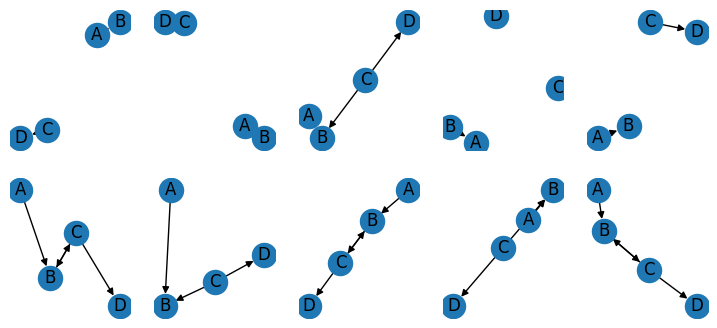

In [64]:
plt.figure(figsize=(9, 4)) 
env = create_env()  
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)  
    env.draw(i, labels=node_labels, amat=expert_amat[i].cpu().numpy()) 

## Draw graphs from the GFlowNet weighted by the expert's model

In [28]:
gflownet.eval() 
graphs, _, log_rewards = sample_massive_batch(gflownet, create_env, num_batches=128) 

  6%|▋         | 8/127 [00:00<00:03, 35.30it/s]

100%|██████████| 127/127 [00:03<00:00, 36.57it/s]


In [50]:
expert_weights = fpost(
    graphs.edge_marks, feedbacks, priors, queries, pi
).mean(dim=1) 

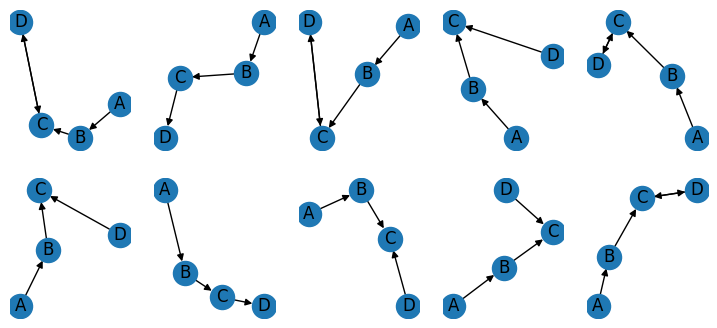

In [51]:
plt.figure(figsize=(9, 4)) 
indices = torch.topk(expert_weights, k=10).indices 
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)  
    graphs.draw(i, labels=node_labels) 